
# T05 — MLP from scratch para classificação do conjunto Iris

**Autor:** Bruno Sime Ferreira Nunes — GRR20190568  
**Professor:** Eduardo Todt  
**Disciplina:** Visão Computacional e Percepção  

Este notebook revisa e depura a implementação fornecida, implementa uma MLP usando apenas NumPy para a rede e o backpropagation, e compara quatro configurações. O objetivo é classificar corretamente as três espécies de Iris e analisar convergência, erros e overfitting.

Notebook-base estudado: [MLP from Scratch](https://colab.research.google.com/drive/19gTFcbqcULM9NBX3Z9a8lE10P_Ju5mG_?usp=sharing).



## 1. Principais problemas encontrados no notebook-base

1. O construtor padrão usa `iasHiddenValue`, mas depois consulta `BiasHiddenValue`, gerando erro quando `params=None`.
2. `predict` aplica apenas multiplicações lineares e ignora as ativações usadas no treinamento.
3. Os vieses são atualizados dentro dos laços dos pesos, portanto recebem a mesma correção várias vezes por amostra.
4. O delta da camada oculta é calculado depois de alterar os pesos da saída; o backpropagation deve usar os pesos do mesmo passo direto.
5. A soma do erro adiciona parciais acumuladas e não corresponde ao MSE declarado.
6. Não há padronização, conjunto de validação, embaralhamento a cada época nem early stopping.
7. Para classes mutuamente exclusivas, softmax com entropia cruzada é mais apropriada do que três sigmoides independentes.

A versão abaixo corrige esses pontos com operações vetorizadas, inicialização Xavier/He, softmax numericamente estável, entropia cruzada, mini-batches, L2 e parada antecipada opcional.


In [1]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)


Amostras: 150 | atributos: 4 | classes: ['setosa', 'versicolor', 'virginica']


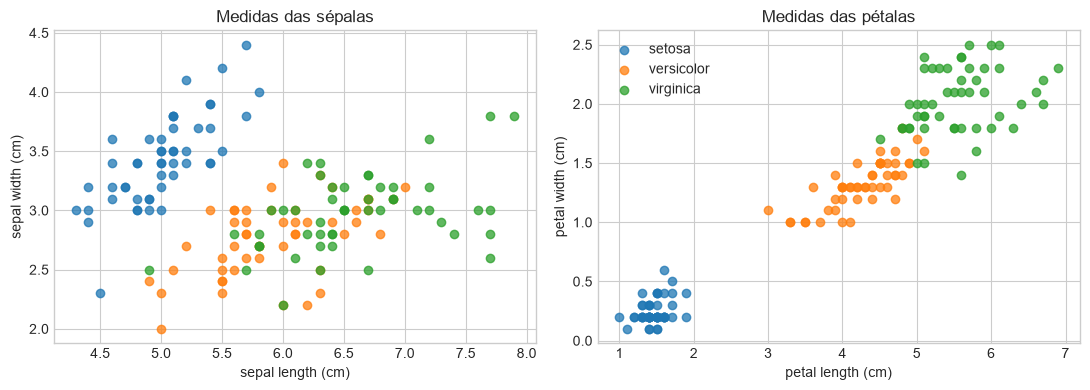

In [2]:

iris = load_iris()
X, y = iris.data, iris.target

print(f"Amostras: {X.shape[0]} | atributos: {X.shape[1]} | classes: {iris.target_names.tolist()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for classe, nome in enumerate(iris.target_names):
    mask = y == classe
    axes[0].scatter(X[mask, 0], X[mask, 1], label=nome, alpha=.75)
    axes[1].scatter(X[mask, 2], X[mask, 3], label=nome, alpha=.75)
axes[0].set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[1], title="Medidas das sépalas")
axes[1].set(xlabel=iris.feature_names[2], ylabel=iris.feature_names[3], title="Medidas das pétalas")
axes[1].legend()
plt.tight_layout()
plt.show()



As classes se sobrepõem nas medidas das sépalas. Nas pétalas, *setosa* é separável, enquanto *versicolor* e *virginica* formam a fronteira difícil. Espera-se que quase todos os erros ocorram entre essas duas classes.


In [3]:

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
X_train_std = (X_train_raw - mean) / std
X_val_std = (X_val_raw - mean) / std
X_test_std = (X_test_raw - mean) / std

print("Treino/validação/teste:", len(y_train), len(y_val), len(y_test))
print("Contagem por classe no teste:", np.bincount(y_test))
print("Média do treino padronizado:", X_train_std.mean(axis=0).round(5))


Treino/validação/teste: 90 30 30
Contagem por classe no teste: [10 10 10]
Média do treino padronizado: [-0. -0. -0.  0.]


## 2. Implementação corrigida da MLP

In [4]:
class MLPFromScratch:
    """MLP de uma camada oculta, treinada apenas com NumPy."""

    def __init__(
        self,
        n_inputs,
        n_hidden=12,
        n_outputs=3,
        activation="tanh",
        learning_rate=0.05,
        l2=0.0,
        epochs=2000,
        batch_size=16,
        patience=None,
        seed=0,
    ):
        self.n_inputs = n_inputs
        self.n_hidden = n_hidden
        self.n_outputs = n_outputs
        self.activation_name = activation
        self.learning_rate = learning_rate
        self.l2 = l2
        self.epochs = epochs
        self.batch_size = batch_size
        self.patience = patience
        self.seed = seed

    @staticmethod
    def _softmax(z):
        z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def _activation(self, z):
        if self.activation_name == "tanh":
            return np.tanh(z)
        if self.activation_name == "relu":
            return np.maximum(0.0, z)
        if self.activation_name == "sigmoid":
            z = np.clip(z, -40, 40)
            return 1.0 / (1.0 + np.exp(-z))
        raise ValueError(self.activation_name)

    def _activation_derivative(self, activated, z):
        if self.activation_name == "tanh":
            return 1.0 - activated**2
        if self.activation_name == "relu":
            return (z > 0).astype(float)
        if self.activation_name == "sigmoid":
            return activated * (1.0 - activated)
        raise ValueError(self.activation_name)

    @staticmethod
    def _one_hot(y, n_classes):
        return np.eye(n_classes)[y.astype(int)]

    def _initialize(self):
        rng = np.random.default_rng(self.seed)
        if self.activation_name == "relu":
            scale1 = np.sqrt(2.0 / self.n_inputs)
        else:
            scale1 = np.sqrt(1.0 / self.n_inputs)
        self.W1 = rng.normal(0, scale1, (self.n_inputs, self.n_hidden))
        self.b1 = np.zeros((1, self.n_hidden))
        self.W2 = rng.normal(0, np.sqrt(1.0 / self.n_hidden), (self.n_hidden, self.n_outputs))
        self.b2 = np.zeros((1, self.n_outputs))

    def _forward(self, X):
        z1 = X @ self.W1 + self.b1
        a1 = self._activation(z1)
        z2 = a1 @ self.W2 + self.b2
        probs = self._softmax(z2)
        return z1, a1, probs

    def _loss(self, X, y):
        y_onehot = self._one_hot(y, self.n_outputs)
        probs = self._forward(X)[2]
        ce = -np.mean(np.sum(y_onehot * np.log(probs + 1e-12), axis=1))
        reg = 0.5 * self.l2 * (np.sum(self.W1**2) + np.sum(self.W2**2))
        return ce + reg

    def fit(self, X_train, y_train, X_val, y_val):
        self._initialize()
        rng = np.random.default_rng(self.seed + 10000)
        y_train_onehot = self._one_hot(y_train, self.n_outputs)
        self.history_ = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
        best_loss = np.inf
        best_state = None
        best_epoch = 0
        wait = 0

        for epoch in range(self.epochs):
            order = rng.permutation(len(X_train))
            for start in range(0, len(X_train), self.batch_size):
                idx = order[start : start + self.batch_size]
                xb = X_train[idx]
                yb = y_train_onehot[idx]
                z1, a1, probs = self._forward(xb)
                m = len(xb)

                dz2 = (probs - yb) / m
                dW2 = a1.T @ dz2 + self.l2 * self.W2
                db2 = np.sum(dz2, axis=0, keepdims=True)
                dz1 = (dz2 @ self.W2.T) * self._activation_derivative(a1, z1)
                dW1 = xb.T @ dz1 + self.l2 * self.W1
                db1 = np.sum(dz1, axis=0, keepdims=True)

                self.W1 -= self.learning_rate * dW1
                self.b1 -= self.learning_rate * db1
                self.W2 -= self.learning_rate * dW2
                self.b2 -= self.learning_rate * db2

            train_loss = self._loss(X_train, y_train)
            val_loss = self._loss(X_val, y_val)
            train_acc = accuracy_score(y_train, self.predict(X_train))
            val_acc = accuracy_score(y_val, self.predict(X_val))
            self.history_["train_loss"].append(train_loss)
            self.history_["val_loss"].append(val_loss)
            self.history_["train_acc"].append(train_acc)
            self.history_["val_acc"].append(val_acc)

            if val_loss < best_loss - 1e-6:
                best_loss = val_loss
                best_epoch = epoch + 1
                best_state = tuple(x.copy() for x in (self.W1, self.b1, self.W2, self.b2))
                wait = 0
            else:
                wait += 1

            if self.patience is not None and wait >= self.patience:
                break

        self.n_epochs_ = len(self.history_["train_loss"])
        self.best_epoch_ = best_epoch
        if self.patience is not None and best_state is not None:
            self.W1, self.b1, self.W2, self.b2 = best_state
        return self

    def predict_proba(self, X):
        return self._forward(X)[2]

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)





## 3. Protocolo experimental

O particionamento estratificado usa 60% para treino, 20% para validação e 20% para teste. Cada configuração é repetida com dez inicializações. O teste é mantido separado do ajuste. As configurações permitem isolar o efeito da padronização e observar a diferença entre uma rede regularizada e uma rede grande sem regularização.


In [5]:

configs = {
    "A — sigmoid sem padronização": dict(n_hidden=5, activation="sigmoid", learning_rate=.01, l2=0., epochs=1500, batch_size=1, patience=None, standardized=False),
    "B — tanh padronizada": dict(n_hidden=8, activation="tanh", learning_rate=.05, l2=0., epochs=1500, batch_size=16, patience=None, standardized=True),
    "C — tanh + L2 + early stopping": dict(n_hidden=12, activation="tanh", learning_rate=.05, l2=.001, epochs=2500, batch_size=16, patience=180, standardized=True),
    "D — 64 ReLU sem regularização": dict(n_hidden=64, activation="relu", learning_rate=.02, l2=0., epochs=2500, batch_size=8, patience=None, standardized=True),
}

rows, representative_models = [], {}
for name, config0 in configs.items():
    config = config0.copy()
    standardized = config.pop("standardized")
    Xt, Xv, Xs = ((X_train_std, X_val_std, X_test_std) if standardized
                  else (X_train_raw, X_val_raw, X_test_raw))
    for seed in range(10):
        model = MLPFromScratch(4, n_outputs=3, seed=seed, **config).fit(Xt, y_train, Xv, y_val)
        train_acc = accuracy_score(y_train, model.predict(Xt))
        val_acc = accuracy_score(y_val, model.predict(Xv))
        test_acc = accuracy_score(y_test, model.predict(Xs))
        rows.append({
            "configuração": name, "semente": seed,
            "épocas": model.n_epochs_, "melhor época": model.best_epoch_,
            "treino": train_acc, "validação": val_acc, "teste": test_acc,
            "gap treino-val": train_acc - val_acc,
        })
        if seed == 7:
            representative_models[name] = (model, Xt, Xv, Xs)

results = pd.DataFrame(rows)
summary = results.groupby("configuração").agg(
    teste_médio=("teste", "mean"), desvio_teste=("teste", "std"),
    treino_médio=("treino", "mean"), validação_média=("validação", "mean"),
    gap_médio=("gap treino-val", "mean"), épocas_médias=("épocas", "mean")
).round(4)
summary


,teste_médio,desvio_teste,treino_médio,validação_média,gap_médio,épocas_médias
configuração,,,,,,
A — sigmoid sem padronização,0.9567,0.0353,0.9744,0.9900,-0.0156,1500.0
B — tanh padronizada,0.9033,0.0105,1.0000,0.9667,0.0333,1500.0
C — tanh + L2 + early stopping,0.9500,0.0176,0.9900,0.9333,0.0567,457.4
D — 64 ReLU sem regularização,0.9333,0.0000,1.0000,0.9667,0.0333,2500.0



## 4. Convergência e overfitting

Convergência é observada pela queda das perdas de treino e validação. Overfitting é indicado quando a perda de treino continua caindo, mas a perda de validação deixa de melhorar, acompanhada de um intervalo entre as acurácias de treino e validação.


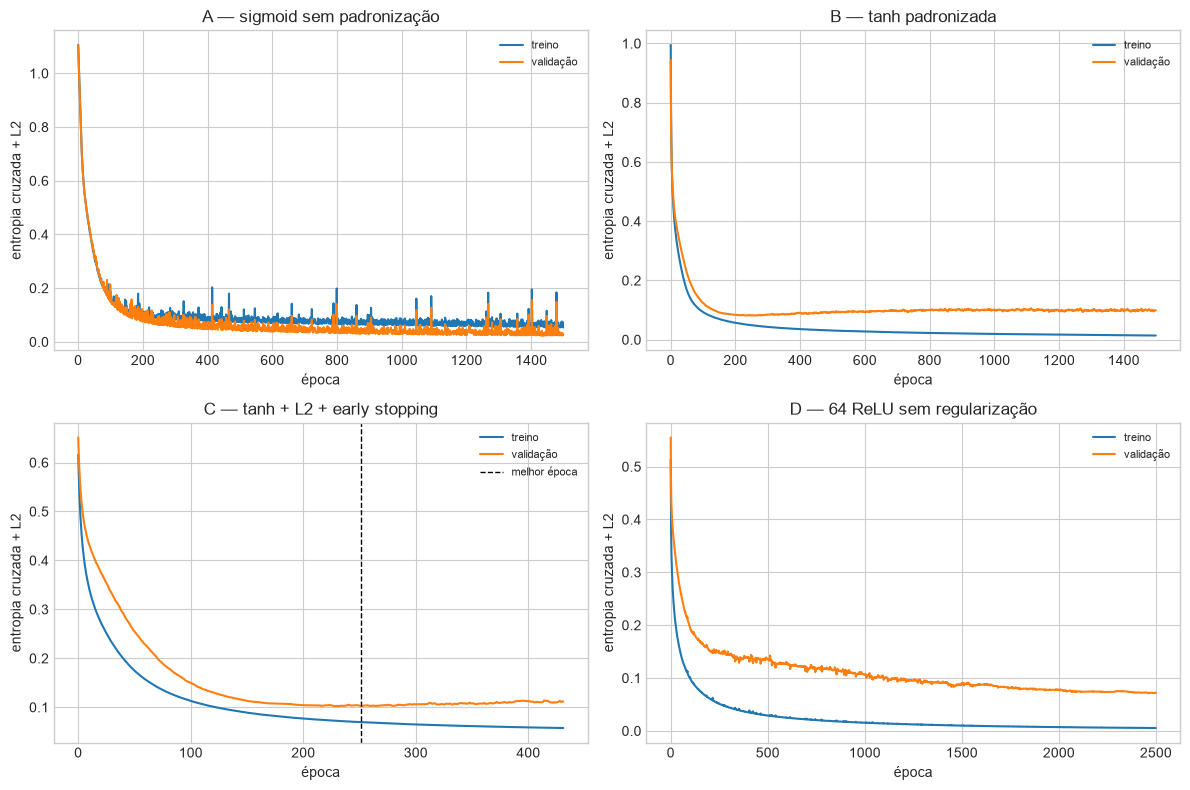

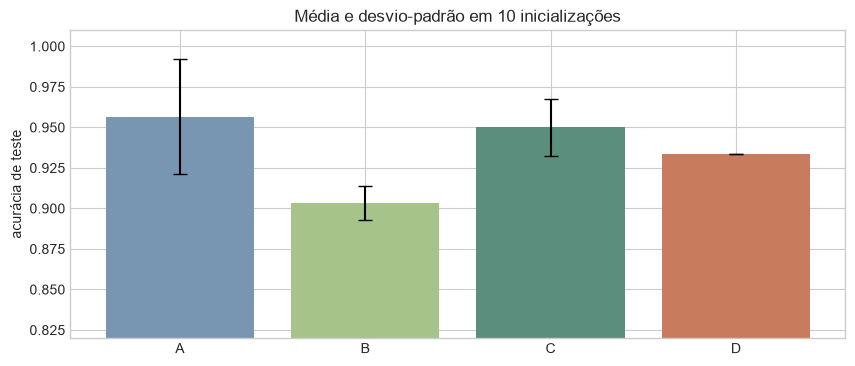

In [6]:

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False)
for ax, (name, (model, *_)) in zip(axes.flat, representative_models.items()):
    ax.plot(model.history_["train_loss"], label="treino")
    ax.plot(model.history_["val_loss"], label="validação")
    if model.patience is not None:
        ax.axvline(model.best_epoch_ - 1, color="black", ls="--", lw=1, label="melhor época")
    ax.set(title=name, xlabel="época", ylabel="entropia cruzada + L2")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
order = list(configs)
means = [results.loc[results["configuração"] == n, "teste"].mean() for n in order]
stds = [results.loc[results["configuração"] == n, "teste"].std() for n in order]
ax.bar(range(4), means, yerr=stds, capsize=5, color=["#7895B2", "#A6C48A", "#5B8E7D", "#C97C5D"])
ax.set_xticks(range(4), ["A", "B", "C", "D"])
ax.set_ylim(.82, 1.01)
ax.set_ylabel("acurácia de teste")
ax.set_title("Média e desvio-padrão em 10 inicializações")
plt.show()



A configuração A atinge a maior média, mas apresenta a maior variabilidade entre inicializações e necessita das 1.500 épocas. A configuração C converge em menos épocas e mantém resultado equilibrado com regularização, embora a pequena validação (30 amostras) torne diferenças de um único exemplo visíveis em saltos de 3,33 pontos percentuais. A configuração D memoriza o treino (100%) e continua reduzindo a perda de treino, sem ganho equivalente de generalização: é o sinal mais claro de overfitting.


## 5. Resultado detalhado e análise dos erros

Configuração: C — tanh + L2 + early stopping | semente: 7
Acurácia de teste: 0.9667
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9091    1.0000    0.9524        10
   virginica     1.0000    0.9000    0.9474        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



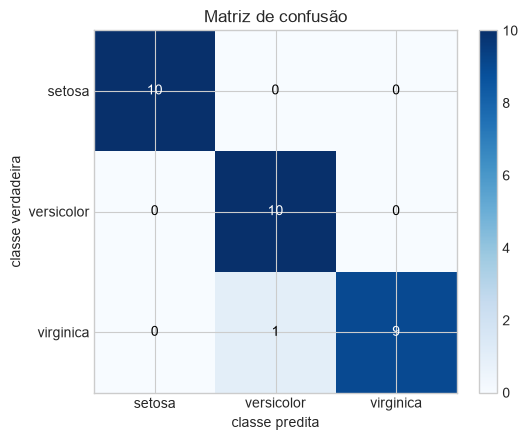

In [7]:

selected_name = "C — tanh + L2 + early stopping"
selected, _, _, X_test_selected = representative_models[selected_name]
pred = selected.predict(X_test_selected)
proba = selected.predict_proba(X_test_selected)
cm = confusion_matrix(y_test, pred)

print(f"Configuração: {selected_name} | semente: 7")
print(f"Acurácia de teste: {accuracy_score(y_test, pred):.4f}")
print(classification_report(y_test, pred, target_names=iris.target_names, digits=4))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), iris.target_names)
ax.set_yticks(range(3), iris.target_names)
ax.set(xlabel="classe predita", ylabel="classe verdadeira", title="Matriz de confusão")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout()
plt.show()


In [8]:

errors = np.where(pred != y_test)[0]
error_rows = []
for i in errors:
    error_rows.append({
        "índice no teste": int(i),
        "verdadeira": iris.target_names[y_test[i]],
        "predita": iris.target_names[pred[i]],
        "confiança": float(proba[i, pred[i]]),
        **{name: float(value) for name, value in zip(iris.feature_names, X_test_raw[i])},
    })
pd.DataFrame(error_rows)


,índice no teste,verdadeira,predita,confiança,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,23,virginica,versicolor,0.705881,6.3,2.8,5.1,1.5



O modelo selecionado classificou corretamente todas as *setosa* e *versicolor* e errou apenas uma *virginica*, confundida com *versicolor*. Esse padrão coincide com a sobreposição vista no gráfico das pétalas. Assim, o erro restante é compatível com a ambiguidade do conjunto e não com incapacidade de separar as três classes.

## 6. Conclusão

A depuração tornou o fluxo direto e o backpropagation consistentes e eliminou o cálculo incorreto dos vieses e do erro. A MLP regularizada selecionada atingiu **96,67%** no teste, com F1 macro de aproximadamente **0,967**, e classificou bem as três classes. A análise também mostrou que acurácia de treino perfeita não garante melhor teste: a rede grande continuou ajustando o treino e apresentou generalização inferior. Para este conjunto pequeno, uma camada oculta modesta, softmax, entropia cruzada, inicialização adequada e monitoramento da validação oferecem a melhor relação entre desempenho, estabilidade e complexidade.
